In [2]:
import numpy as np
import pandas as pd
from Bio import SeqIO
import matplotlib as mpl
from matplotlib.font_manager import FontProperties
from typing import Optional, Dict, Tuple, List
mpl.rcParams['svg.fonttype'] = 'none'
# Path to your Arial.ttf file
arial_font_path = '/Users/skawakubo/python/fonts/Arial.ttf'
# Create a FontProperties object for the Arial font
arial_font = FontProperties(fname=arial_font_path)
mpl.rcParams['font.family'] = arial_font.get_name()
import matplotlib.pyplot as plt

In [22]:
fasta_path = 'FCoV1_full_nt_ginsi_Izumi_250824.fasta'

ids = []
seqs = []

for rec in SeqIO.parse(fasta_path, 'fasta'):
    ids.append(rec.id)
    seqs.append(str(rec.seq))

df_fasta = pd.DataFrame({'ID': ids, 'Seq': seqs})
df_fasta

,ID,Seq
0,KY566209.1,ACTAACTCGAATCATAGCTAGTAGCTAAATGCATTATGCTGGTGAG...
1,PP254206.1,----------------------------------------------...
2,PP254207.1,----------------------------------------------...
3,PP254208.1,----------------------------------------------...
4,PP254209.1,----------------------------------------------...
...,...,...
139,FECV47,----------------------------------------------...
140,FECV5,------------GTTGGTTCCGGTCTCGATCGAGGGAAACTAGTCC...
141,FECV51,----------------------------------------------...
142,FECV66,----------------------------------------------...


In [23]:
df_meta = pd.read_csv('FCoV_all_full_meta_250830_modified.tsv', sep='\t')
df_meta

,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,Source,Note,FECV_or_FIPV,Unnamed: 10
0,NC_002306.3,79-1146,NaN,USA,NaN,NaN,29355.0,NCBI,NaN,FIPV,NaN
1,PP254206.1,ZD/22/332i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,NaN
2,PP254207.1,ZD/22/337i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,NaN
3,PP254208.1,ZD/22/385i,2022/7/19,India,Felis catus,feces,29286.0,NCBI,NaN,FECV,NaN
4,PP254209.1,ZD/22/519i,2022/7/21,India,Felis catus,feces,29221.0,NCBI,NaN,FECV,NaN
...,...,...,...,...,...,...,...,...,...,...,...
157,FECV43,FECV43,2025/6/16,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,NaN
158,FECV46,FECV46,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,NaN
159,FECV47,FECV47,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,NaN
160,FECV51,FECV51,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,NaN


In [24]:
df_merged = pd.merge(df_fasta, df_meta, left_on='ID', right_on='Accession')
df_merged

,ID,Seq,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,Source,Note,FECV_or_FIPV,Unnamed: 10
0,KY566209.1,ACTAACTCGAATCATAGCTAGTAGCTAAATGCATTATGCTGGTGAG...,KY566209.1,NaN,16-Nov,China,Felis catus,abdominal cavity,29440.0,NCBI,NaN,FIPV,NaN
1,PP254206.1,----------------------------------------------...,PP254206.1,ZD/22/332i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,NaN
2,PP254207.1,----------------------------------------------...,PP254207.1,ZD/22/337i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,NaN
3,PP254208.1,----------------------------------------------...,PP254208.1,ZD/22/385i,2022/7/19,India,Felis catus,feces,29286.0,NCBI,NaN,FECV,NaN
4,PP254209.1,----------------------------------------------...,PP254209.1,ZD/22/519i,2022/7/21,India,Felis catus,feces,29221.0,NCBI,NaN,FECV,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,FECV47,----------------------------------------------...,FECV47,FECV47,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,NaN
140,FECV5,------------GTTGGTTCCGGTCTCGATCGAGGGAAACTAGTCC...,FECV5,FECV5,2025/6/16,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,NaN
141,FECV51,----------------------------------------------...,FECV51,FECV51,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,NaN
142,FECV66,----------------------------------------------...,FECV66,FECV66,2025/7/7,Japan,Felis catus,feces,NaN,Izumi,NaN,FECV,NaN


In [25]:
alndf = df_merged.set_index('ID')
# alndf['Seq'] = alndf['Seq'].to_list()
# alndf.columns = list(range(alndf.shape[1]))
# alndf.head(20)
# ignore index name
alndf.index.name = None
alndf = alndf.drop(columns="Seq").join(
    alndf["Seq"].apply(lambda x: pd.Series(list(x)))
)

In [26]:
alndf.head(10)

,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,Source,Note,FECV_or_FIPV,...,29724,29725,29726,29727,29728,29729,29730,29731,29732,29733
KY566209.1,KY566209.1,NaN,16-Nov,China,Felis catus,abdominal cavity,29440.0,NCBI,NaN,FIPV,...,-,-,-,-,-,-,-,-,-,-
PP254206.1,PP254206.1,ZD/22/332i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254207.1,PP254207.1,ZD/22/337i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254208.1,PP254208.1,ZD/22/385i,2022/7/19,India,Felis catus,feces,29286.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254209.1,PP254209.1,ZD/22/519i,2022/7/21,India,Felis catus,feces,29221.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254210.1,PP254210.1,ZD/22/561i,2022/7/22,India,Felis catus,feces,29199.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254211.1,PP254211.1,ZD/22/563i,2022/7/22,India,Felis catus,feces,29175.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254215.1,PP254215.1,Cat/MP/Or-Re/ZD/22-01/Di2,2022/1/31,India,Felis catus,feces,29219.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP908789.1,PP908789.1,FCoV/Thailand/CU27724/2021,21-Aug,Thailand,Felis catus,feces,29055.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP908790.1,PP908790.1,FCoV/Thailand/CUFIP486/2021,21-Feb,Thailand,Felis catus,abdominal fluid,28711.0,NCBI,NaN,FIPV,...,-,-,-,-,-,-,-,-,-,-


In [27]:
alndf['FECV_or_FIPV'].value_counts()

FECV_or_FIPV
unknown    55
FECV       49
FIPV       40
Name: count, dtype: int64

In [28]:
alndf = alndf[alndf['FECV_or_FIPV'] != 'unknown']  

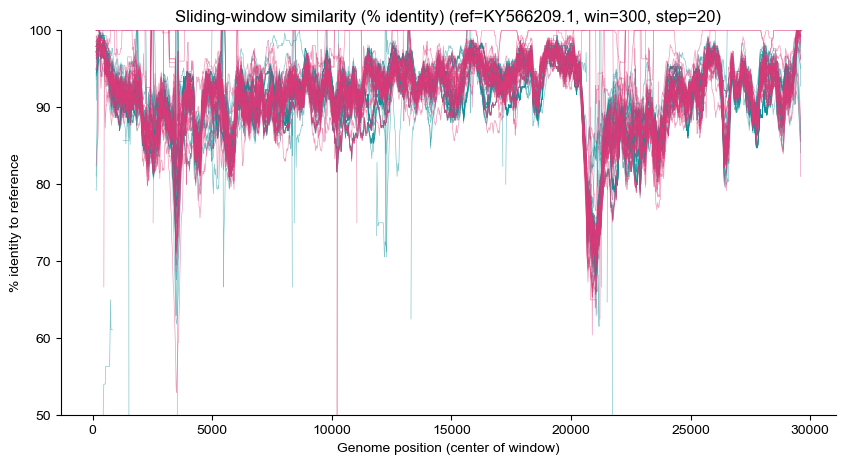

In [36]:
reference_id: Optional[str] = "KY566209.1"   # e.g., "Ref_01"; if None, uses the first row
window_size: int = 300 # 300 seems good
step_size: int = 20 # 50 seems good

# Category source (pick ONE). If both are provided, category_series takes priority.
category_series: Optional[pd.Series] = None  # index=seq_id, value=category
category_col_in_alndf: Optional[str] = "FECV_or_FIPV"  # e.g., "category" (a column in alndf with categories)

# Similarity / plotting options
out_svg = "similarity_plot.svg"
ignore_gaps_and_ambiguous: bool = True
valid_chars = set("ACGTacgt")         # considered comparable when ignoring gaps/ambiguous
plot_category_mean: bool = False
per_sequence_alpha: float = 0.5
ylim_range = (50, 100)  # e.g., (0, 100) or None
title: str = "Sliding-window similarity (% identity)"
show_legend: bool = True


my_colors = {
    "FECV": "#089099",
    "FIPV": "#DC3977"
}

def _validate_alignment_df(df: pd.DataFrame) -> Tuple[np.ndarray, List[str]]:
    """Validate shape and return (char_matrix, seq_ids)."""
    if df is None or df.shape[0] == 0 or df.shape[1] == 0:
        raise ValueError("alndf appears empty. Ensure rows are sequences and columns are alignment positions.")
    # Ensure single-character entries as strings
    arr = df.astype(str).values  # shape (n_seq, L)
    # quick sanity check: all rows equal length by DataFrame construction
    seq_ids = [str(x) for x in df.index.tolist()]
    return arr, seq_ids

def _choose_reference_id(seq_ids: List[str], ref_id: Optional[str]) -> str:
    if ref_id is None:
        return seq_ids[0]
    if ref_id not in seq_ids:
        raise ValueError(f"reference_id '{ref_id}' not found. Available (first 10): {seq_ids[:10]}")
    return ref_id

def _build_category_map(
    seq_ids: List[str],
    category_series: Optional[pd.Series],
    alndf: pd.DataFrame,
    category_col_in_alndf: Optional[str],
) -> Dict[str, str]:
    if category_series is not None:
        # Align index to seq_ids; missing -> "Unknown"
        s = category_series.reindex(seq_ids)
        return {sid: (str(cat) if pd.notna(cat) else "Unknown") for sid, cat in s.items()}
    if category_col_in_alndf is not None:
        if category_col_in_alndf not in alndf.columns:
            raise ValueError(f"'{category_col_in_alndf}' not found in alndf columns.")
        s = alndf[category_col_in_alndf].astype(str)
        return {sid: s.loc[sid] if sid in s.index else "Unknown" for sid in seq_ids}
    # Default single category
    return {sid: "All" for sid in seq_ids}

def _window_indices(seq_len: int, win: int, step: int) -> List[Tuple[int, int]]:
    idx = []
    s = 0
    while s < seq_len:
        e = min(s + win, seq_len)
        if e - s <= 0:
            break
        idx.append((s, e))
        if e == seq_len:
            break
        s += step
    return idx

def _percent_identity_windows_matrix(
    X: np.ndarray,                    # shape (n_seq, L), dtype=str
    ref_idx: int,
    win: int,
    step: int,
    ignore_gaps_and_ambiguous: bool,
    valid_chars: set,
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Vectorized per-window %ID computation.
    Returns:
      centers: shape (n_win,)
      pct_id:  shape (n_seq, n_win) with NaN where denom=0
    """
    n_seq, L = X.shape
    # window indices
    idx = _window_indices(L, win, step)
    centers = np.array([(s+e)/2.0 for s, e in idx], dtype=float)
    n_win = len(idx)
    out = np.full((n_seq, n_win), np.nan, dtype=float)

    # Pre-encode valid mask for all positions to avoid repeated `isin` calls
    if ignore_gaps_and_ambiguous:
        vc = np.array([c in valid_chars for c in X.ravel()], dtype=bool).reshape(n_seq, L)
    else:
        vc = np.ones((n_seq, L), dtype=bool)

    for j, (s, e) in enumerate(idx):
        ref_seg = X[ref_idx, s:e]
        # valid positions per sequence: both ref and query are valid chars
        if ignore_gaps_and_ambiguous:
            mask_ref = vc[ref_idx, s:e]  # shape (win_len,)
        else:
            mask_ref = np.ones(e - s, dtype=bool)

        # Broadcast ref_seg to all sequences
        q_seg = X[:, s:e]                         # (n_seq, win_len)
        mask_q = vc[:, s:e] if ignore_gaps_and_ambiguous else np.ones_like(q_seg, dtype=bool)

        both_valid = mask_q & mask_ref  # broadcasting: (n_seq, win_len)
        denom = both_valid.sum(axis=1)  # (n_seq,)
        matches = (q_seg == ref_seg) & both_valid
        num = matches.sum(axis=1)

        with np.errstate(invalid="ignore", divide="ignore"):
            out[:, j] = np.where(denom > 0, (num / denom) * 100.0, np.nan)

    return centers, out

def compute_similarity_from_alndf(
    alndf: pd.DataFrame,
    reference_id: Optional[str],
    window_size: int,
    step_size: int,
    category_series: Optional[pd.Series] = None,
    category_col_in_alndf: Optional[str] = None,
    ignore_gaps_and_ambiguous: bool = True,
    valid_chars: set = set("ACGTacgt"),
) -> pd.DataFrame:
    """
    Compute sliding-window % identity from an existing alignment DataFrame.
    Returns long-form DataFrame:
      columns = [seq_id, category, win_start, win_end, pos_center, pct_identity]
    """
    # If a category column is embedded in alndf, drop it from the character matrix
    char_cols = alndf.columns
    if category_col_in_alndf and category_col_in_alndf in char_cols:
        char_cols = [c for c in char_cols if c != category_col_in_alndf]
        X_char = alndf[char_cols]
    else:
        X_char = alndf

    X, seq_ids = _validate_alignment_df(X_char)
    ref_id = _choose_reference_id(seq_ids, reference_id)
    ref_idx = seq_ids.index(ref_id)

    # numeric window bounds come from the number of columns (alignment length)
    L = X.shape[1]
    idx = _window_indices(L, window_size, step_size)

    centers, pct_matrix = _percent_identity_windows_matrix(
        X, ref_idx, window_size, step_size, ignore_gaps_and_ambiguous, valid_chars
    )

    # Build category map
    cat_map = _build_category_map(seq_ids, category_series, alndf, category_col_in_alndf)

    # Assemble long-form results
    records = []
    for i, sid in enumerate(seq_ids):
        for (s, e), center, pid in zip(idx, centers, pct_matrix[i, :]):
            records.append({
                "seq_id": sid,
                "category": cat_map.get(sid, "Unknown"),
                "win_start": int(s),
                "win_end": int(e),
                "pos_center": float(center),
                "pct_identity": float(pid) if pd.notna(pid) else np.nan
            })
    return pd.DataFrame.from_records(records)

def plot_similarity_by_category(
    df: pd.DataFrame,
    title: str = "Sliding-window similarity (% identity)",
    ylim: Optional[Tuple[float,float]] = None,
    per_sequence_alpha: float = 0.25,
    plot_category_mean: bool = True,
    show_legend: bool = True,
    color_map: Optional[Dict[str,str]] = None,
    out_svg: str = out_svg
):
    if df is None or df.empty:
        raise ValueError("Empty results DataFrame.")
    categories = sorted(df["category"].astype(str).unique().tolist())

    # 色の指定
    if color_map is None:
        cmap = plt.get_cmap("tab10")
        color_map = {cat: cmap(i % 10) for i, cat in enumerate(categories)}
    else:
        # 未指定カテゴリはデフォルト色に補う
        for i, cat in enumerate(categories):
            if cat not in color_map:
                cmap = plt.get_cmap("tab10")
                color_map[cat] = cmap(i % 10)

    fig, ax = plt.subplots(figsize=(10, 5))

    # Per-sequence lines
    for (cat, sid), g in df.groupby(["category", "seq_id"]):
        ax.plot(g["pos_center"].values, g["pct_identity"].values,
                lw=0.5, alpha=per_sequence_alpha, color=color_map[cat])

    # Category mean lines (thicker)
    if plot_category_mean:
        for cat, g in df.groupby("category"):
            mean_df = g.groupby("pos_center", as_index=False)["pct_identity"].mean()
            ax.plot(mean_df["pos_center"].values, mean_df["pct_identity"].values,
                    lw=0.5, color=color_map[cat], label=f"{cat} (mean)")

    ax.set_xlabel("Genome position (center of window)")
    ax.set_ylabel("% identity to reference")
    ax.set_title(title)
    if ylim is not None:
        ax.set_ylim(*ylim) 
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if show_legend and plot_category_mean:
        ax.legend(loc="best", ncol=2, fontsize=9)
    fig.savefig(out_svg, format="svg", bbox_inches="tight", transparent=True)

results_df = compute_similarity_from_alndf(
    alndf=alndf,
    reference_id=reference_id,
    window_size=window_size,
    step_size=step_size,
    category_series=category_series,
    category_col_in_alndf=category_col_in_alndf,
    ignore_gaps_and_ambiguous=ignore_gaps_and_ambiguous,
    valid_chars=valid_chars,
)
results_df = results_df[results_df["seq_id"] != reference_id]
ref_show = reference_id if reference_id is not None else str(alndf.index.tolist()[0])
plot_similarity_by_category(
    results_df,
    title=f"{title} (ref={ref_show}, win={window_size}, step={step_size})",
    ylim=ylim_range,
    per_sequence_alpha=per_sequence_alpha,
    plot_category_mean=plot_category_mean,
    show_legend=show_legend,
    color_map=my_colors,
    out_svg=out_svg
)

In [ ]:
import plotly.graph_objects as go
import plotly.express as px
import numpy as np
import pandas as pd
from typing import Optional, Dict, Tuple

def plot_similarity_interactive(
    df: pd.DataFrame,
    title: str = "Sliding-window similarity (% identity)",
    ylim: Optional[Tuple[float, float]] = None, # example: (95, 100)
    plot_category_mean: bool = True,
    per_sequence_alpha: float = 0.25,
    color_map: Optional[Dict[str, str]] = None, 
    width: int = 1800,
    height: int = 700,
):
    if df is None or df.empty:
        raise ValueError("Empty results DataFrame.")
    df = df.copy()
    df["category"] = df["category"].astype(str)
    df["seq_id"] = df["seq_id"].astype(str)

    categories = sorted(df["category"].unique())

    if color_map is None:
        palette = px.colors.qualitative.Set2
        color_map = {cat: palette[i % len(palette)] for i, cat in enumerate(categories)}
    else:
        palette = px.colors.qualitative.Set2
        for i, cat in enumerate(categories):
            color_map.setdefault(cat, palette[i % len(palette)])

    fig = go.Figure()

    for (cat, sid), g in df.groupby(["category", "seq_id"]):
        fig.add_trace(go.Scattergl(
            x=g["pos_center"], y=g["pct_identity"],
            mode="lines",
            line=dict(width=1, color=color_map[cat]),
            opacity=per_sequence_alpha,
            name=f"{cat} | {sid}",
            legendgroup=cat,
            hovertemplate=(
                "seq: %{customdata[0]}<br>"
                "category: %{customdata[1]}<br>"
                "pos: %{x:.0f}<br>"
                "identity: %{y:.2f}%<extra></extra>"
            ),
            customdata=np.stack([g["seq_id"], g["category"]], axis=1)
        ))

    # Category mean lines (thicker)
    if plot_category_mean:
        for cat, g in df.groupby("category"):
            mean_df = g.groupby("pos_center", as_index=False)["pct_identity"].mean()
            fig.add_trace(go.Scattergl(
                x=mean_df["pos_center"], y=mean_df["pct_identity"],
                mode="lines",
                line=dict(width=3, color=color_map[cat]),
                name=f"{cat} (mean)",
                legendgroup=cat,
                hovertemplate=(
                    "category: " + cat + "<br>"
                    "pos: %{x:.0f}<br>"
                    "mean identity: %{y:.2f}%<extra></extra>"
                )
            ))

    fig.update_layout(
        title=title,
        xaxis_title="Genome position (center of window)",
        yaxis_title="% identity to reference",
        width=width, height=height,
        hovermode="x unified",
        template="plotly_white",
        legend=dict(itemsizing="trace", orientation="v", xanchor="left", yanchor="bottom", y=0.5, x=1.02)
    )
    if ylim is not None:
        fig.update_yaxes(range=list(ylim))
    fig.write_html("similarity_plot.html", include_plotlyjs="cdn", auto_open=True)

In [39]:
ref_show = reference_id if reference_id is not None else str(alndf.index.tolist()[0])
plot_similarity_interactive(
    results_df,
    title=f"{title} (ref={ref_show}, win={window_size}, step={step_size})",
    ylim=(50, 100),  
    plot_category_mean=True,
    per_sequence_alpha=0.25,
    color_map=my_colors
)

### Plotting only selected seqs

In [40]:
alndf.head(10)

,Accession,Isolate,Collection_Date,Country,Host,Tissue_Specimen_Source,Length,Source,Note,FECV_or_FIPV,...,29724,29725,29726,29727,29728,29729,29730,29731,29732,29733
KY566209.1,KY566209.1,NaN,16-Nov,China,Felis catus,abdominal cavity,29440.0,NCBI,NaN,FIPV,...,-,-,-,-,-,-,-,-,-,-
PP254206.1,PP254206.1,ZD/22/332i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254207.1,PP254207.1,ZD/22/337i,2022/7/17,India,Felis catus,feces,29229.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254208.1,PP254208.1,ZD/22/385i,2022/7/19,India,Felis catus,feces,29286.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254209.1,PP254209.1,ZD/22/519i,2022/7/21,India,Felis catus,feces,29221.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254210.1,PP254210.1,ZD/22/561i,2022/7/22,India,Felis catus,feces,29199.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254211.1,PP254211.1,ZD/22/563i,2022/7/22,India,Felis catus,feces,29175.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP254215.1,PP254215.1,Cat/MP/Or-Re/ZD/22-01/Di2,2022/1/31,India,Felis catus,feces,29219.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP908789.1,PP908789.1,FCoV/Thailand/CU27724/2021,21-Aug,Thailand,Felis catus,feces,29055.0,NCBI,NaN,FECV,...,-,-,-,-,-,-,-,-,-,-
PP908790.1,PP908790.1,FCoV/Thailand/CUFIP486/2021,21-Feb,Thailand,Felis catus,abdominal fluid,28711.0,NCBI,NaN,FIPV,...,-,-,-,-,-,-,-,-,-,-


In [ ]:
# selected_seq_ids = ["AY304486.1|cCoV05|SZ3|2003-05", "AY572034.1|cCoV12|civet007|2004-01", "AY394982.1|hCoV01|HGZ8L1-B|2003-01", "NC_004718.3|hCoVepidemic|TOR2|2003-03"]  
# selected_alndf = alndf[alndf.index.isin(selected_seq_ids)]

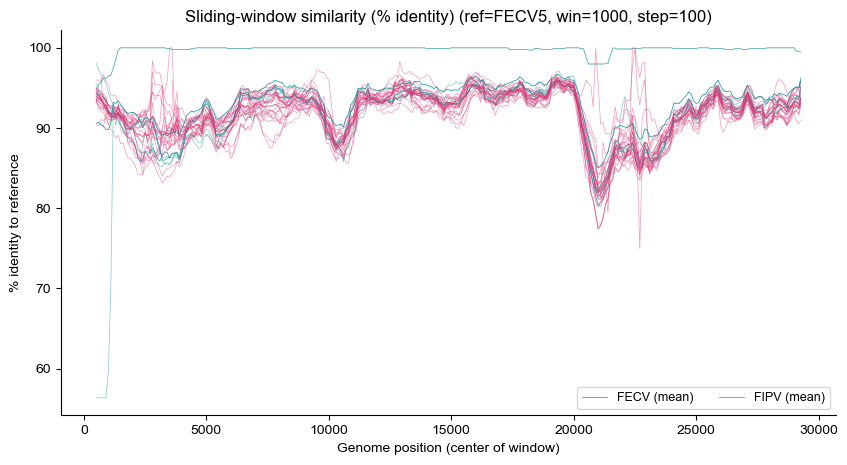

In [43]:
selected_alndf = alndf[alndf['Source'] == 'Izumi']

reference_id: Optional[str] = "FECV5"   # e.g., "Ref_01"; if None, uses the first row
window_size: int = 1000 # 300 seems good, 1000 seems better
step_size: int = 100 # 50 seems good, 100 seems better

# Category source (pick ONE). If both are provided, category_series takes priority.
category_series: Optional[pd.Series] = None  # index=seq_id, value=category
category_col_in_alndf: Optional[str] = "FECV_or_FIPV"  # e.g., "category" (a column in alndf with categories)

# Similarity / plotting options
out_svg = "similarity_plot_selected.svg"
ignore_gaps_and_ambiguous: bool = True
valid_chars = set("ACGTacgt")         # considered comparable when ignoring gaps/ambiguous
plot_category_mean: bool = True
per_sequence_alpha: float = 0.5
ylim_range = None  # e.g., (0, 100) or None
title: str = "Sliding-window similarity (% identity)"
show_legend: bool = True

my_colors = {
    "FECV": "#089099",
    "FIPV": "#DC3977"
}

results_df = compute_similarity_from_alndf(
    alndf=selected_alndf,
    reference_id=reference_id,
    window_size=window_size,
    step_size=step_size,
    category_series=category_series,
    category_col_in_alndf=category_col_in_alndf,
    ignore_gaps_and_ambiguous=ignore_gaps_and_ambiguous,
    valid_chars=valid_chars,
)
results_df = results_df[results_df["seq_id"] != reference_id]
ref_show = reference_id if reference_id is not None else str(alndf.index.tolist()[0])
plot_similarity_by_category(
    results_df,
    title=f"{title} (ref={ref_show}, win={window_size}, step={step_size})",
    ylim=ylim_range,
    per_sequence_alpha=per_sequence_alpha,
    plot_category_mean=plot_category_mean,
    show_legend=show_legend,
    color_map=my_colors,
    out_svg=out_svg
)